In [1]:
import pandas as pd
import numpy as np
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
export_dir = os.getcwd()
from pathlib import Path
import pickle
from collections import defaultdict
import time
import torch
import torch.nn as nn
import copy
import torch.nn.functional as F
import optuna
import logging
import matplotlib.pyplot as plt
import ipynb
import importlib
import sys
from tqdm import tqdm
import multiprocessing
from functools import partial
from concurrent.futures import ProcessPoolExecutor
import torch.multiprocessing as mp
from openpyxl.cell.cell import MergedCell

In [2]:
data_name = "Yahoo" ### Can be ML1M, Yahoo, Pinterest
recommender_name = "MLP" ### Can be MLP, VAE, NCF
DP_DIR = Path("data", data_name) 
export_dir = Path(os.getcwd())
files_path = Path(export_dir, DP_DIR)
checkpoints_path = Path(export_dir, "checkpoints")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
output_type_dict = {
    "VAE":"multiple",
    "MLP":"single",
    "NCF": "single"}

num_users_dict = {
    "ML1M":6037,
    "Yahoo":13797, 
    "Pinterest":19155}

num_items_dict = {
    "ML1M":3381,
    "Yahoo":4604, 
    "Pinterest":9362}


recommender_path_dict = {
    ("ML1M","VAE"): Path(checkpoints_path, "VAE_ML1M_0.0007_128_10.pt"),
    ("ML1M","MLP"):Path(checkpoints_path, "MLP1_ML1M_0.0076_256_7.pt"),
    ("ML1M","NCF"):Path(checkpoints_path, "NCF_ML1M_5e-05_64_16.pt"),
    
    ("Yahoo","VAE"): Path(checkpoints_path, "VAE_Yahoo_0.0001_128_13.pt"),
    ("Yahoo","MLP"):Path(checkpoints_path, "MLP2_Yahoo_0.0083_128_1.pt"),
    ("Yahoo","NCF"):Path(checkpoints_path, "NCF_Yahoo_0.001_64_21_0.pt"),
    
    ("Pinterest","VAE"): Path(checkpoints_path, "VAE_Pinterest_12_18_0.0001_256.pt"),
    ("Pinterest","MLP"):Path(checkpoints_path, "MLP_Pinterest_0.0062_512_21_0.pt"),
    ("Pinterest","NCF"):Path(checkpoints_path, "NCF2_Pinterest_9e-05_32_9_10.pt"),}


hidden_dim_dict = {
    ("ML1M","VAE"): None,
    ("ML1M","MLP"): 32,
    ("ML1M","NCF"): 8,

    ("Yahoo","VAE"): None,
    ("Yahoo","MLP"):32,
    ("Yahoo","NCF"):8,
    
    ("Pinterest","VAE"): None,
    ("Pinterest","MLP"):512,
    ("Pinterest","NCF"): 64,
}

LXR_checkpoint_dict = {
    ("ML1M","VAE"): ('LXR_ML1M_VAE_26_38_128_3.185652725834087_1.420642300151426.pt',128),
    ("ML1M","MLP"): ('LXR_ML1M_MLP_12_39_64_11.59908096547193_0.1414854294885049.pt',64),
    ("ML1M","NCF"): ('LXR_ML1M_NCF_17_38_64_14.950042796023537_0.1778309603009678.pt',64),

    ("Yahoo","VAE"): ('LXR_Yahoo_VAE_neg-1.5pos_combined_19_26_128_18.958765029913238_4.92235962483309.pt',128),
    ("Yahoo","MLP"):('LXR_Yahoo_MLP_neg-pos_combined_last_29_37_128_12.40692505393434_0.19367009952856118.pt',128),
    ("Yahoo","NCF"): ('LXR_Yahoo_NCF_neg-pos_combined_loss_14_14_32_16.01464392466348_6.880015038643981.pt', 32),

    ("Pinterest","VAE"): ('LXR_Pinterest_VAE_comb_4_27_32_6.3443735346179855_1.472868807603448.pt',32),
    ("Pinterest","MLP"): ('LXR_Pinterest_MLP_0_5_16_10.059416809308486_0.705778173474644.pt',16),
    ("Pinterest","NCF"): ('LXR_Pinterest_NCF_combined__neg-1.5pos_0_26_32_13.02585523498726_12.8447247971534.pt', 32)
}

In [4]:
output_type = output_type_dict[recommender_name] ### Can be single, multiple
num_users = num_users_dict[data_name] 
num_items = num_items_dict[data_name] 

hidden_dim = hidden_dim_dict[(data_name,recommender_name)]
recommender_path = recommender_path_dict[(data_name,recommender_name)]

In [5]:
train_data = pd.read_csv(Path(files_path,f'train_data_{data_name}.csv'), index_col=0)
test_data = pd.read_csv(Path(files_path,f'test_data_{data_name}.csv'), index_col=0)
static_test_data = pd.read_csv(Path(files_path,f'static_test_data_{data_name}.csv'), index_col=0)
with open(Path(files_path,f'pop_dict_{data_name}.pkl'), 'rb') as f:
    pop_dict = pickle.load(f)
train_array = train_data.to_numpy()
test_array = test_data.to_numpy()
items_array = np.eye(num_items)
all_items_tensor = torch.Tensor(items_array).to(device)

In [6]:
test_array = static_test_data.iloc[:,:-2].to_numpy()
'''
with open(Path(files_path, f'jaccard_based_sim_{data_name}.pkl'), 'rb') as f:
    jaccard_dict = pickle.load(f) 
with open(Path(files_path, f'cosine_based_sim_{data_name}.pkl'), 'rb') as f:
    cosine_dict = pickle.load(f) 
with open(Path(files_path, f'pop_dict_{data_name}.pkl'), 'rb') as f:
    pop_dict = pickle.load(f) 
with open(Path(files_path, f'item_to_cluster_{recommender_name}_{data_name}.pkl'), 'rb') as f:
    item_to_cluster = pickle.load(f) 
with open(Path(files_path, f'shap_values_{recommender_name}_{data_name}.pkl'), 'rb') as f:
    shap_values= pickle.load(f) 
for i in range(num_items):
    for j in range(i, num_items):
        jaccard_dict[(j,i)]= jaccard_dict[(i,j)]
        cosine_dict[(j,i)]= cosine_dict[(i,j)]
        pop_array = np.zeros(len(pop_dict))

'''
with open(Path(files_path, f'pop_dict_{data_name}.pkl'), 'rb') as f:
    pop_dict = pickle.load(f) 

pop_array={}
for key, value in pop_dict.items():
    pop_array[key] = value
kw_dict = {'device':device,
          'num_items': num_items,
           'num_features': num_items, 
            'demographic':False,
          'pop_array':pop_array,
          'all_items_tensor':all_items_tensor,
          'static_test_data':static_test_data,
          'items_array':items_array,
          'output_type':output_type,
          'recommender_name':recommender_name}

In [7]:
import os


#os.chdir('/storage/mikhail/PI4Rec/code')
print(os.getcwd())

/home/mvarasteh/EvaluationMetrics


In [8]:
sys.path.append('../baselines') 
from ipynb.fs.defs.help_functions import recommender_run
from ipynb.fs.defs.lime import *
from ipynb.fs.defs.lime import *
importlib.reload(ipynb.fs.defs.lime)
from ipynb.fs.defs.lime import *
lime = LimeBase(distance_to_proximity)



from ipynb.fs.defs.help_functions import *
importlib.reload(ipynb.fs.defs.help_functions)
from ipynb.fs.defs.help_functions import *

from ipynb.fs.defs.recommenders_architecture import *
importlib.reload(ipynb.fs.defs.recommenders_architecture)
from ipynb.fs.defs.recommenders_architecture import *

VAE_config= {
"enc_dims": [512,128],
"dropout": 0.5,
"anneal_cap": 0.2,
"total_anneal_steps": 200000}


Pinterest_VAE_config= {
"enc_dims": [256,64],
"dropout": 0.5,
"anneal_cap": 0.2,
"total_anneal_steps": 200000}

In [9]:
def load_recommender():
    if recommender_name == 'MLP':
        recommender = MLP(hidden_dim, **kw_dict)
    elif recommender_name == 'VAE':  # This was incorrectly checking for 'MLP' twice
        if data_name == "Pinterest":
            recommender = VAE(Pinterest_VAE_config, **kw_dict)
        else:
            recommender = VAE(VAE_config, **kw_dict)
    elif recommender_name == 'NCF':
        MLP_temp = MLP_model(hidden_size=hidden_dim, num_layers=3, **kw_dict)
        GMF_temp = GMF_model(hidden_size=hidden_dim, **kw_dict)
        recommender = NCF(factor_num=hidden_dim, num_layers=3, dropout=0.5, model='NeuMF-pre', GMF_model=GMF_temp, MLP_model=MLP_temp, **kw_dict)
    else:
        raise ValueError(f"Unknown recommender name: {recommender_name}")

    # Check if the model's state_dict matches the architecture
    recommender_checkpoint = torch.load(recommender_path, map_location=device)
    recommender.load_state_dict(recommender_checkpoint, strict=False)
    recommender.eval()
    for param in recommender.parameters():
        param.requires_grad = False
    
    return recommender

In [10]:
recommender = load_recommender()

In [11]:
def find_pop_mask(x, item_id):
    user_hist = torch.Tensor(x).to(device) # remove the positive item we want to explain from the user history
    user_hist[item_id] = 0
    item_pop_dict = {}
    
    for i,j in enumerate(user_hist>0):
        if j:
            item_pop_dict[i]=pop_array[i] # add the pop of the item to the dictionary
            
    return item_pop_dict

In [12]:
#User based similarities using Jaccard
def find_jaccard_mask(x, item_id, user_based_Jaccard_sim):
    user_hist = x # remove the positive item we want to explain from the user history
    user_hist[item_id] = 0
    item_jaccard_dict = {}
    for i,j in enumerate(user_hist>0):
        if j:
            if (i,item_id) in user_based_Jaccard_sim:
                item_jaccard_dict[i]=user_based_Jaccard_sim[(i,item_id)] # add Jaccard similarity between items
            else:
                item_jaccard_dict[i] = 0            

    return item_jaccard_dict

In [13]:
#Cosine based similarities between users and items
def find_cosine_mask(x, item_id, item_cosine):
    user_hist = x # remove the positive item we want to explain from the user history
    user_hist[item_id] = 0
    item_cosine_dict = {}
    for i,j in enumerate(user_hist>0):
        if j:
            if (i,item_id) in item_cosine:
                item_cosine_dict[i]=item_cosine[(i,item_id)]
            else:
                item_cosine_dict[i]=0

    return item_cosine_dict

In [14]:
class Explainer(nn.Module):
    def __init__(self, user_size, item_size, hidden_size):
        super(Explainer, self).__init__()
        
        self.users_fc = nn.Linear(in_features = user_size, out_features=hidden_size).to(device)
        self.items_fc = nn.Linear(in_features = item_size, out_features=hidden_size).to(device)
        self.bottleneck = nn.Sequential(
            nn.Tanh(),
            nn.Linear(in_features = hidden_size*2, out_features=hidden_size).to(device),
            nn.Tanh(),
            nn.Linear(in_features = hidden_size, out_features=user_size).to(device),
            nn.Sigmoid()
        ).to(device)
        
        
    def forward(self, user_tensor, item_tensor):
        user_output = self.users_fc(user_tensor.float())
        item_output = self.items_fc(item_tensor.float())
        combined_output = torch.cat((user_output, item_output), dim=-1)
        expl_scores = self.bottleneck(combined_output).to(device)
        return expl_scores

In [15]:
def find_lxr_mask(x, item_tensor, explainer):
    user_hist = x
    expl_scores = explainer(user_hist, item_tensor)
    
    # Debug: Print the explainer scores and user history
    print(f"Explainer scores: {expl_scores[:5]}")
    print(f"User history before masking: {user_hist[:5]}")
    
    x_masked = user_hist * expl_scores
    
    # Debug: Print masked user history
    print(f"User history after masking: {x_masked[:5]}")
    
    item_sim_dict = {}
    for i, j in enumerate(x_masked != 0):
        if j:
            item_sim_dict[i] = x_masked[i]
    
    return item_sim_dict


In [16]:
def load_explainer(fine_tuning=False, lambda_pos=None, lambda_neg=None, alpha=None):
    lxr_path, lxr_dim = LXR_checkpoint_dict[(data_name, recommender_name)]
    explainer = Explainer(num_items, num_items, lxr_dim)
    lxr_checkpoint = torch.load(Path(checkpoints_path, lxr_path))
    explainer.load_state_dict(lxr_checkpoint)
    explainer.eval()
    for param in explainer.parameters():
        param.requires_grad = False
    return explainer

In [17]:
def find_lime_mask(x, item_id, min_pert, max_pert, num_of_perturbations, kernel_func, feature_selection, recommender, num_samples=10, method = 'POS', **kw_dict):
    user_hist = x # remove the positive item we want to explain from the user history
    user_hist[item_id] = 0
    lime.kernel_fn = kernel_func
    neighborhood_data, neighborhood_labels, distances, item_id = get_lime_args(user_hist, item_id, recommender, all_items_tensor, min_pert = min_pert, max_pert = max_pert, num_of_perturbations = num_of_perturbations, seed = item_id, **kw_dict)
    if method=='POS':
        most_pop_items  = lime.explain_instance_with_data(neighborhood_data, neighborhood_labels, distances, item_id, num_samples, feature_selection, pos_neg='POS')
    if method=='NEG':
        most_pop_items  = lime.explain_instance_with_data(neighborhood_data, neighborhood_labels, distances, item_id, num_samples, feature_selection ,pos_neg='NEG')
        
    return most_pop_items 

In [18]:
def find_lire_mask(x, item_id, num_of_perturbations, kernel_func, feature_selection, recommender, proba=0.1, method = 'POS', **kw_dict):
    user_hist = x # remove the positive item we want to explain from the user history
    user_hist[item_id] = 0
    lime.kernel_fn = kernel_func

    neighborhood_data, neighborhood_labels, distances, item_id = get_lire_args(user_hist, item_id, recommender, all_items_tensor, train_array, num_of_perturbations = num_of_perturbations, seed = item_id, proba=0.1, **kw_dict)
    if method=='POS':
        most_pop_items  = lime.explain_instance_with_data(neighborhood_data, neighborhood_labels, distances, item_id, num_of_perturbations, feature_selection, pos_neg='POS')
    if method=='NEG':
        most_pop_items  = lime.explain_instance_with_data(neighborhood_data, neighborhood_labels, distances, item_id, num_of_perturbations, feature_selection ,pos_neg='NEG')
        
    return most_pop_items

In [19]:
def find_fia_mask(user_tensor, item_tensor, item_id, recommender):
    y_pred = recommender_run(user_tensor, recommender, item_tensor, item_id, **kw_dict).to(device)
    items_fia = {}
    user_hist = user_tensor.cpu().detach().numpy().astype(int)
    
    for i in range(num_items):
        if(user_hist[i] == 1):
            user_hist[i] = 0
            user_tensor = torch.FloatTensor(user_hist).to(device)
            y_pred_without_item = recommender_run(user_tensor, recommender, item_tensor, item_id, 'single', **kw_dict).to(device)
            infl_score = y_pred - y_pred_without_item
            items_fia[i] = infl_score
            user_hist[i] = 1

    return items_fia

In [20]:
def find_shapley_mask(user_tensor, user_id, model, shap_values, item_to_cluster):
    item_shap = {}
    shapley_values = shap_values[shap_values[:, 0].astype(int) == user_id][:,1:]
    user_vector = user_tensor.cpu().detach().numpy().astype(int)

    for i in np.where(user_vector.astype(int) == 1)[0]:
        items_cluster = item_to_cluster[i]
        item_shap[i] = shapley_values.T[int(items_cluster)][0]

    return item_shap  

In [21]:
def find_accent_mask(user_tensor, user_id, item_tensor, item_id, recommender_model, top_k):
   
    items_accent = defaultdict(float)
    factor = top_k - 1
    user_accent_hist = user_tensor.cpu().detach().numpy().astype(int)

    #Get topk items
    sorted_indices = list(get_top_k(user_tensor, user_tensor, recommender_model, **kw_dict).keys())
    
    if top_k == 1:
        # When k=1, return the index of the first maximum value
        top_k_indices = [sorted_indices[0]]
    else:
        top_k_indices = sorted_indices[:top_k]
   

    for iteration, item_k_id in enumerate(top_k_indices):

        # Set topk items to 0 in the user's history
        user_accent_hist[item_k_id] = 0
        user_tensor = torch.FloatTensor(user_accent_hist).to(device)
       
        item_vector = items_array[item_k_id]
        item_tensor = torch.FloatTensor(item_vector).to(device)
              
        # Check influence of the items in the history on this specific item in topk
        fia_dict = find_fia_mask(user_tensor, item_tensor, item_k_id, recommender_model)
         
        # Sum up all differences between influence on top1 and other topk values
        if not iteration:
            for key in fia_dict.keys():
                items_accent[key] *= factor
        else:
            for key in fia_dict.keys():
                items_accent[key] -= fia_dict[key]
       
    for key in items_accent.keys():
        items_accent[key] *= -1    

    return items_accent

In [22]:
def single_user_expl(user_vector, user_tensor, item_id, item_tensor, num_items, recommender_model, user_id = None, mask_type = None):
    '''
    This function invokes various explanation functions
    and returns a dictionary of explanations, sorted by their scores.
    '''
    user_hist_size = np.sum(user_vector)

    if mask_type == 'lime':
        POS_sim_items = find_lime_mask(user_vector, item_id, 50, 100, 150, distance_to_proximity, 'highest_weights', recommender_model, num_samples=user_hist_size, **kw_dict)
        NEG_sim_items = find_lime_mask(user_vector, item_id, 50, 100, 150, distance_to_proximity, 'highest_weights', recommender_model, num_samples=user_hist_size, method='NEG', **kw_dict)
    elif mask_type == 'lire':
        POS_sim_items = find_lire_mask(user_vector, item_id, 200, distance_to_proximity, 'highest_weights', recommender_model, proba=0.1, **kw_dict)
        NEG_sim_items = find_lire_mask(user_vector, item_id, 200, distance_to_proximity, 'highest_weights', recommender_model, proba=0.1, method='NEG', **kw_dict)
    else:
        if mask_type == 'cosine':
            sim_items = find_cosine_mask(user_tensor, item_id, cosine_dict)
        elif mask_type == 'shap':
            sim_items = find_shapley_mask(user_tensor, user_id, recommender_model, shap_values, item_to_cluster)
        elif mask_type == 'accent':
            sim_items = find_accent_mask(user_tensor, user_id, item_tensor, item_id, recommender_model, 5)
        elif mask_type == 'lxr':
            explainer = load_explainer(True)
            sim_items = find_lxr_mask(user_tensor, item_tensor, explainer)

        POS_sim_items = list(sorted(sim_items.items(), key=lambda item: item[1], reverse=True))[0:user_hist_size]


In [23]:
'''
def single_user_metrics(user_vector, user_tensor, item_id, item_tensor,num_steps, recommender_model, expl_dict, **kw_dict):
    """
    Calculate metrics for a single user with 5 steps of item masking
    Now explicitly includes POS@20 and NEG@20 metrics
    """
    POS_masked = user_tensor.clone()
    NEG_masked = user_tensor.clone()
    POS_masked[item_id] = 0
    NEG_masked[item_id] = 0
    
    # Use 5 steps
   # num_steps = 5
    bins = range(1, num_steps + 1)  # [1, 2, 3, 4, 5]
    
    # Initialize metric arrays with 5 elements each
    POS_at_5 = [0] * num_steps
    POS_at_10 = [0] * num_steps
    POS_at_20 = [0] * num_steps  # Explicitly initialize POS@20
    
    NEG_at_5 = [0] * num_steps
    NEG_at_10 = [0] * num_steps
    NEG_at_20 = [0] * num_steps  # Explicitly initialize NEG@20
    
    DEL = [0] * num_steps
    INS = [0] * num_steps
    NDCG = [0] * num_steps
    
    # Get sorted items by importance
    POS_sim_items = expl_dict
    NEG_sim_items = list(sorted(dict(POS_sim_items).items(), key=lambda item: item[1], reverse=False))
    
    # For each step (1 to 5 items)
    for i, num_items_to_mask in enumerate(bins):
        # Create masks for positive and negative cases
        POS_masked = torch.zeros_like(user_tensor, dtype=torch.float32, device=kw_dict['device'])
        NEG_masked = torch.zeros_like(user_tensor, dtype=torch.float32, device=kw_dict['device'])
        
        # Apply POS masking
        for j in POS_sim_items[:num_items_to_mask]:
            POS_masked[j[0]] = 1
        POS_masked = user_tensor * (1 - POS_masked)
        
        # Apply NEG masking
        for j in NEG_sim_items[:num_items_to_mask]:
            NEG_masked[j[0]] = 1
        NEG_masked = user_tensor * (1 - NEG_masked)
        
        # Get rankings for both POS and NEG
        POS_ranked_list = get_top_k(POS_masked, user_tensor, recommender_model, **kw_dict)
        NEG_ranked_list = get_top_k(NEG_masked, user_tensor, recommender_model, **kw_dict)
        #print(f"POS_ranked_list: {POS_ranked_list}")
        # Calculate POS ranking
        if item_id in list(POS_ranked_list.keys()):
            POS_index = list(POS_ranked_list.keys()).index(item_id) + 1
        else:
            POS_index = kw_dict['num_items']
            
        # Calculate NEG ranking
        if item_id in list(NEG_ranked_list.keys()):
            NEG_index = list(NEG_ranked_list.keys()).index(item_id) + 1
        else:
            NEG_index = kw_dict['num_items']
        
        # Calculate ALL metrics including P@20
        POS_at_5[i] = 1 if POS_index <= 5 else 0
        POS_at_10[i] = 1 if POS_index <= 10 else 0
        POS_at_20[i] = 1 if POS_index <= 20 else 0  # Explicitly calculate POS@20
        
        NEG_at_5[i] = 1 if NEG_index <= 5 else 0
        NEG_at_10[i] = 1 if NEG_index <= 10 else 0
        NEG_at_20[i] = 1 if NEG_index <= 20 else 0  # Explicitly calculate NEG@20
        
        # Calculate other metrics
        DEL[i] = float(recommender_run(POS_masked, recommender_model, item_tensor, item_id, **kw_dict).detach().cpu().numpy())
        INS[i] = float(recommender_run(user_tensor - POS_masked, recommender_model, item_tensor, item_id, **kw_dict).detach().cpu().numpy())
        NDCG[i] = get_ndcg(list(POS_ranked_list.keys()), item_id, **kw_dict)
    
    # Return all metrics including P@20
    res = [DEL, INS, NDCG, 
           POS_at_5, POS_at_10, POS_at_20,  # Include POS@20
           NEG_at_5, NEG_at_10, NEG_at_20]  # Include NEG@20
    return [np.array(x) for x in res]

'''

'\ndef single_user_metrics(user_vector, user_tensor, item_id, item_tensor,num_steps, recommender_model, expl_dict, **kw_dict):\n    """\n    Calculate metrics for a single user with 5 steps of item masking\n    Now explicitly includes POS@20 and NEG@20 metrics\n    """\n    POS_masked = user_tensor.clone()\n    NEG_masked = user_tensor.clone()\n    POS_masked[item_id] = 0\n    NEG_masked[item_id] = 0\n    \n    # Use 5 steps\n   # num_steps = 5\n    bins = range(1, num_steps + 1)  # [1, 2, 3, 4, 5]\n    \n    # Initialize metric arrays with 5 elements each\n    POS_at_5 = [0] * num_steps\n    POS_at_10 = [0] * num_steps\n    POS_at_20 = [0] * num_steps  # Explicitly initialize POS@20\n    \n    NEG_at_5 = [0] * num_steps\n    NEG_at_10 = [0] * num_steps\n    NEG_at_20 = [0] * num_steps  # Explicitly initialize NEG@20\n    \n    DEL = [0] * num_steps\n    INS = [0] * num_steps\n    NDCG = [0] * num_steps\n    \n    # Get sorted items by importance\n    POS_sim_items = expl_dict\n    NEG

In [24]:
class MetricsBaselines:
    def __init__(self, data_name, recommender_name):
        self.data_name = data_name
        self.recommender_name = recommender_name
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.setup_data_and_recommender()

    def setup_data_and_recommender(self):
        # Set up all necessary data and variables
        DP_DIR = Path("processed_data", self.data_name)
        self.files_path = Path(export_dir.parent, DP_DIR)
        self.num_users = num_users_dict[self.data_name]
        self.num_items = num_items_dict[self.data_name]
        
        self.test_data = pd.read_csv(Path(self.files_path, f'test_data_{self.data_name}.csv'), index_col=0)
        self.test_array = self.test_data.to_numpy()
        self.items_array = np.eye(self.num_items)
        
        with open(Path(self.files_path, f'pop_dict_{self.data_name}.pkl'), 'rb') as f:
            self.pop_dict = pickle.load(f)
        
        # Load other necessary data (jaccard_dict, cosine_dict, item_to_cluster, shap_values)
        
        self.kw_dict = {
            'device': self.device,
            'num_items': self.num_items,
            'num_features': self.num_items,
            'demographic': False,
            'pop_array': np.array([self.pop_dict.get(i, 0) for i in range(self.num_items)]),
            'all_items_tensor': torch.eye(self.num_items).to(self.device),
            'static_test_data': self.test_data,
            'items_array': self.items_array,
            'output_type': output_type_dict[self.recommender_name],
            'recommender_name': self.recommender_name,
            'files_path': self.files_path
        }
        
        self.recommender = self.load_recommender()

In [25]:
def process_user(user_index, test_array, test_data, recommender, kw_dict):
    try:
        user_vector = test_array[user_index]
        user_tensor = torch.FloatTensor(user_vector).to(kw_dict['device'])
        user_id = int(test_data.index[user_index])

        item_id = int(get_user_recommended_item(user_tensor, recommender, **kw_dict).detach().cpu().numpy())
        item_vector = kw_dict['items_array'][item_id]
        item_tensor = torch.FloatTensor(item_vector).to(kw_dict['device'])

        user_vector[item_id] = 0
        user_tensor[item_id] = 0

        results = {}
        for method in ['pop', 'jaccard', 'cosine', 'lime', 'lxr', 'accent', 'shap']:
            results[method] = single_user_expl(user_vector, user_tensor, item_id, item_tensor, kw_dict['num_items'], recommender, mask_type=method, user_id=user_id if method == 'shap' else None)

        return user_id, results
    except Exception as e:
        print(f"Error processing user {user_id}: {str(e)}")
        return None

In [26]:
def rbo_similarity(list1, list2, p=0.9):
    """
    Rank-Biased Overlap (extrapolated, RBO_ext) between two ranked lists.
    Webber et al. (2010), eq. 32. Handles uneven lengths; assumes no duplicates.
        1.0 = identical rankings
        0.0 = no common items
    p in (0, 1) controls top-weightedness: smaller p puts more weight on the top ranks.
    """
    if not list1 or not list2:
        return 0.0
    if not 0 < p < 1:
        raise ValueError("p must be in (0, 1)")

    # S = shorter list, L = longer list
    S, L = (list1, list2) if len(list1) <= len(list2) else (list2, list1)
    s, l = len(S), len(L)

    seen_S, seen_L = set(), set()
    overlap = 0
    X = [0] * (l + 1)  # X[d] = overlap size at depth d

    for d in range(1, l + 1):
        if d <= s:
            x = S[d - 1]
            if x in seen_L:
                overlap += 1
            seen_S.add(x)
        y = L[d - 1]
        if y in seen_S:
            overlap += 1
        seen_L.add(y)
        X[d] = overlap

    sum1 = sum(X[d] / d * p**d for d in range(1, l + 1))
    sum2 = sum(X[s] * (d - s) / (s * d) * p**d for d in range(s + 1, l + 1))

    return (1 - p) / p * (sum1 + sum2) + ((X[l] - X[s]) / l + X[s] / s) * p**l

In [27]:
"""
Conventional and list-aware fidelity metrics (simplified).

Expected to exist in your environment:
    get_top_k, recommender_run, get_user_recommended_item,
    data_name, recommender_name, files_path, recommender,
    test_array, test_data, items_array, device, kw_dict

All scores and ranks come from get_top_k, which returns {item: score} for every item not in
the user's history, sorted by score. Run check_scores() once to confirm these scores match
recommender_run.
"""
import pickle
import warnings
from pathlib import Path

import numpy as np
import torch
from tqdm import tqdm

K = 20          # list length
TAU = 0.7       # list-similarity threshold for Counterfactual Validity
C = 5           # ODR offset for Rank Degradation
RBO_P = 0.9     # RBO persistence

METRICS = [
    # Conventional (target only)
    'DEL', 'INS', 'POS_at_5', 'POS_at_10', 'POS_at_20', 'CDCG', 'NONTARGET_CDCG',
        'NONTARGET_POS_at_5', 'NONTARGET_POS_at_10', 'NONTARGET_POS_at_20',

    # Counterfactual Validity
    'COV_CV', 'LS', 'LS_SUCC',
    # Necessity, Sufficiency, Rank Degradation
    'COV_NEC', 'DELTA_NEC',
    'COV_SUF', 'DELTA_SUF',
    'COV_RD', 'DELTA_RD', 'ODR_T', 'ODR_NT',
]
# DEL, INS      target score after removing / keeping only the explanation
# POS_at_n      1 if the target left the top-n after removal
# CDCG          1 / log2(rank_after + 1) of the target (lower = better)
# COV_CV        target left the top-K AND LS >= TAU
# LS            RBO between the top-K lists (target excluded) before and after removal
# LS_SUCC       LS, only for users whose target left the top-K (NaN otherwise)
# COV_x         1 if the target is affected more than the mean non-target item
# DELTA_x       mean non-target effect minus target effect (higher = better)


# ====================================================================== #
#  Helpers                                                                #
# ====================================================================== #
def rbo_similarity(list1, list2, p=RBO_P):
    """Extrapolated RBO (Webber et al., 2010, eq. 32). 1 = identical, 0 = disjoint."""
    if not list1 or not list2:
        return 0.0
    S, L = (list1, list2) if len(list1) <= len(list2) else (list2, list1)
    s, l = len(S), len(L)
    seen_S, seen_L, overlap = set(), set(), 0
    X = [0] * (l + 1)
    for d in range(1, l + 1):
        if d <= s:
            if S[d - 1] in seen_L:
                overlap += 1
            seen_S.add(S[d - 1])
        if L[d - 1] in seen_S:
            overlap += 1
        seen_L.add(L[d - 1])
        X[d] = overlap
    sum1 = sum(X[d] / d * p**d for d in range(1, l + 1))
    sum2 = sum(X[s] * (d - s) / (s * d) * p**d for d in range(s + 1, l + 1))
    return (1 - p) / p * (sum1 + sum2) + ((X[l] - X[s]) / l + X[s] / s) * p**l


def odr(rank_before, rank_after, c):
    """Offset-discounted rank. 1 = unchanged, < 1 = dropped, > 1 = moved up."""
    return np.log2(rank_before + c) / np.log2(rank_after + c)
    #return 1 / np.log2(rank_after - rank_before+ 5)


def odr_cdcg(rank_before, rank_after, c):
    """Offset-discounted rank. 1 = unchanged, < 1 = dropped, > 1 = moved up."""
    return 1 / np.log2(max((rank_after - rank_before), 0)+2)
    
def ratio(new, old, eps=1e-8):
    """new / old; NaN if old is ~0."""
    return new / old if abs(old) > eps else np.nan


def ranks(scored):
    """{item: score} sorted by score -> {item: 1-based rank}."""
    return {it: r + 1 for r, it in enumerate(scored)}


# ====================================================================== #
#  Per-user metrics                                                       #
# ====================================================================== #
def single_user_metrics(user_tensor, t, expl, model, num_steps, tau=TAU, c=C, **kw):
    """
    user_tensor : user history with the target t already set to 0
    expl        : list of (item, importance), most important first
    Returns {metric: array of length num_steps}, one value per K_e = 1..num_steps.
    """
    orig = get_top_k(user_tensor, user_tensor, model, **kw)
    orig_items, orig_rank = list(orig), ranks(orig)

    non_targets = [x for x in orig_items[:K] if x != t]       # N_u = L_K(x_u) \ {t}
    list_wo_t   = [x for x in orig_items if x != t][:K]       # L_K^{-t}(x_u)
    expl_sorted = sorted(expl.items() if hasattr(expl, 'items') else expl,
                         key=lambda e: e[1], reverse=True)
    expl_items = [int(e[0]) for e in expl_sorted if user_tensor[int(e[0])] > 0]   # history items only

    out = {m: np.full(num_steps, np.nan) for m in METRICS}

    for i in range(num_steps):
        k = i + 1
        mask = torch.zeros_like(user_tensor)
        mask[torch.tensor(expl_items[:k], dtype=torch.long)] = 1

        rem = get_top_k(user_tensor * (1 - mask), user_tensor, model, **kw)   # explanation removed
        kep = get_top_k(user_tensor * mask,       user_tensor, model, **kw)   # only explanation kept
        rem_items, rem_rank = list(rem), ranks(rem)
        rank_t = rem_rank[t]

        # --- Conventional (target only) ---
        out['DEL'][i] = rem[t]
        out['INS'][i] = kep[t]
        for n in (5, 10, 20):
            out[f'POS_at_{n}'][i] = float(rank_t > n)
            # share of non-target items that dropped by at least n positions
            out[f'NONTARGET_POS_at_{n}'][i] = np.mean(
                [rem_rank[j] - orig_rank[j] >= n for j in non_targets])
        out['CDCG'][i] = odr_cdcg(1, rank_t, 1)
        out['NONTARGET_CDCG'][i] = np.mean([odr_cdcg(orig_rank[j], rem_rank[j], 5) for j in non_targets])
        # --- Counterfactual Validity ---
        ls = rbo_similarity(list_wo_t, [x for x in rem_items if x != t][:K])
        out['LS'][i] = ls
        if rank_t > K:
            out['LS_SUCC'][i] = ls
        out['COV_CV'][i] = float(rank_t > K and ls >= tau)

        with warnings.catch_warnings():
            warnings.simplefilter('ignore', RuntimeWarning)   # nanmean of an all-NaN list

            # --- Necessity: share of score left after removal ---
            d_t   = ratio(rem[t], orig[t])
            d_bar = np.nanmean([ratio(rem[j], orig[j]) for j in non_targets])
            out['COV_NEC'][i]   = float(d_t < d_bar)
            out['DELTA_NEC'][i] = d_bar - d_t

            # --- Sufficiency: share of score kept with only the explanation ---
            r_t   = ratio(kep[t], orig[t])
            r_bar = np.nanmean([ratio(kep[j], orig[j]) for j in non_targets])
            out['COV_SUF'][i]   = float(r_t > r_bar)
            out['DELTA_SUF'][i] = r_t - r_bar

        o_t   = odr(orig_rank[t], rank_t, c)
        o_bar = np.mean([odr(orig_rank[j], rem_rank[j], c) for j in non_targets])
        out['ODR_T'][i]    = o_t
        out['ODR_NT'][i]   = o_bar
        out['COV_RD'][i]   = float(o_t < o_bar)
        out['DELTA_RD'][i] = o_bar - o_t

    return out


# ====================================================================== #
#  Evaluation over all users                                              #
# ====================================================================== #
def eval_one_expl_type(expl_name, num_steps=10, tau=TAU, c=C):
    print(f' ============ {data_name} {recommender_name} explained by {expl_name} ============')

    with open(Path(files_path, f'{recommender_name}_{expl_name}_expl_dict.pkl'), 'rb') as f:
        expl_dict = pickle.load(f)

    recommender.eval()
    per_user = {m: [] for m in METRICS}

    with torch.no_grad():
        for i in tqdm(range(test_array.shape[0])):
            user_tensor = torch.FloatTensor(test_array[i].copy()).to(device)
            user_id = int(test_data.index[i])

            t = int(get_user_recommended_item(user_tensor, recommender, **kw_dict).detach().cpu().numpy())
            user_tensor[t] = 0

            res = single_user_metrics(user_tensor, t, expl_dict[user_id], recommender,
                                      num_steps, tau=tau, c=c, **kw_dict)
            for m in METRICS:
                per_user[m].append(res[m])

    # Mean over users, ignoring NaN (e.g., LS_SUCC for users whose target stayed in the top-K)
    results = {}
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        for m in METRICS:
            results[m] = np.nanmean(np.stack(per_user[m]), axis=0)
    results['NUM_USERS'] = test_array.shape[0]

    for m in METRICS:
        print(f'{m:>10}_{expl_name}: K_e={num_steps}: {results[m][-1]:.4f}   '
              f'per K_e: {np.round(results[m], 4)}')

    return results


def check_scores(n_users=3):
    """Run once: get_top_k scores should equal recommender_run scores."""
    with torch.no_grad():
        for i in range(n_users):
            ut = torch.FloatTensor(test_array[i].copy()).to(device)
            t = int(get_user_recommended_item(ut, recommender, **kw_dict).detach().cpu().numpy())
            ut[t] = 0
            it = torch.FloatTensor(items_array[t]).to(device)
            single = float(recommender_run(ut, recommender, it, t, **kw_dict).detach().cpu().numpy())
            vector = get_top_k(ut, ut, recommender, **kw_dict)[t]
            print(f'user {i}: recommender_run={single:.6f}  get_top_k={vector:.6f}  diff={abs(single - vector):.2e}')

In [38]:
exp_model_name="lxr"
metrics=eval_one_expl_type(exp_model_name,num_steps=10, tau=0.7, c=5)

 ============ Yahoo MLP explained by lxr ============


100%|██████████| 2760/2760 [06:04<00:00,  7.58it/s]


       DEL_lxr: K_e=10: 0.6641   per K_e: [0.9101 0.8722 0.839  0.8089 0.7801 0.7536 0.7289 0.7058 0.6844 0.6641]
       INS_lxr: K_e=10: 0.9391   per K_e: [0.647  0.7613 0.8321 0.8746 0.9009 0.9168 0.9266 0.9327 0.9366 0.9391]
  POS_at_5_lxr: K_e=10: 0.8080   per K_e: [0.0851 0.2221 0.3482 0.4594 0.5543 0.6257 0.6877 0.7366 0.7757 0.808 ]
 POS_at_10_lxr: K_e=10: 0.6775   per K_e: [0.0478 0.1409 0.2312 0.3134 0.4014 0.4772 0.538  0.5888 0.633  0.6775]
 POS_at_20_lxr: K_e=10: 0.5830   per K_e: [0.0236 0.0996 0.1681 0.237  0.3127 0.379  0.4446 0.4928 0.542  0.583 ]
      CDCG_lxr: K_e=10: 0.2775   per K_e: [0.8146 0.6776 0.5813 0.5061 0.4455 0.395  0.3574 0.3259 0.3    0.2775]
NONTARGET_CDCG_lxr: K_e=10: 0.3391   per K_e: [0.7298 0.6315 0.5677 0.5181 0.4747 0.439  0.408  0.3827 0.3591 0.3391]
NONTARGET_POS_at_5_lxr: K_e=10: 0.7463   per K_e: [0.1911 0.3368 0.4333 0.5066 0.5686 0.618  0.6592 0.6923 0.7213 0.7463]
NONTARGET_POS_at_10_lxr: K_e=10: 0.6865   per K_e: [0.1122 0.2376 0.3328 0.4

In [67]:
metrics

{'DEL': array([0.96742682, 0.95708424, 0.94478708, 0.93120044, 0.9166244 ,
        0.90156887, 0.8861341 , 0.87048327, 0.85532363, 0.8400497 ]),
 'INS': array([0.6880641 , 0.74843838, 0.79463106, 0.83080117, 0.85876039,
        0.88100927, 0.89867641, 0.91269316, 0.92387049, 0.93310286]),
 'POS_at_5': array([0.00248344, 0.01076159, 0.04221854, 0.06622517, 0.09768212,
        0.12417219, 0.1589404 , 0.19784768, 0.21274834, 0.24337748]),
 'POS_at_10': array([0.00082781, 0.00413907, 0.01821192, 0.04139073, 0.05380795,
        0.07781457, 0.09519868, 0.11258278, 0.14072848, 0.17135762]),
 'POS_at_20': array([0.00082781, 0.00082781, 0.00745033, 0.02069536, 0.03807947,
        0.05049669, 0.06622517, 0.08360927, 0.10016556, 0.12003311]),
 'CDCG': array([0.95615713, 0.91562767, 0.86959325, 0.83221071, 0.79756152,
        0.76407088, 0.73107777, 0.70073392, 0.67422509, 0.64536169]),
 'NONTARGET_CDCG': array([0.87164084, 0.82475924, 0.78716377, 0.75684495, 0.72846986,
        0.70370363, 0.6822

In [36]:
import pickle
from pathlib import Path

file_path = Path(files_path, f'{recommender_name}_{exp_model_name}_metrics.pkl')

with open(file_path, 'wb') as f:
    pickle.dump(metrics, f)

## Ploting

NameError: name 'exp_model_name' is not defined

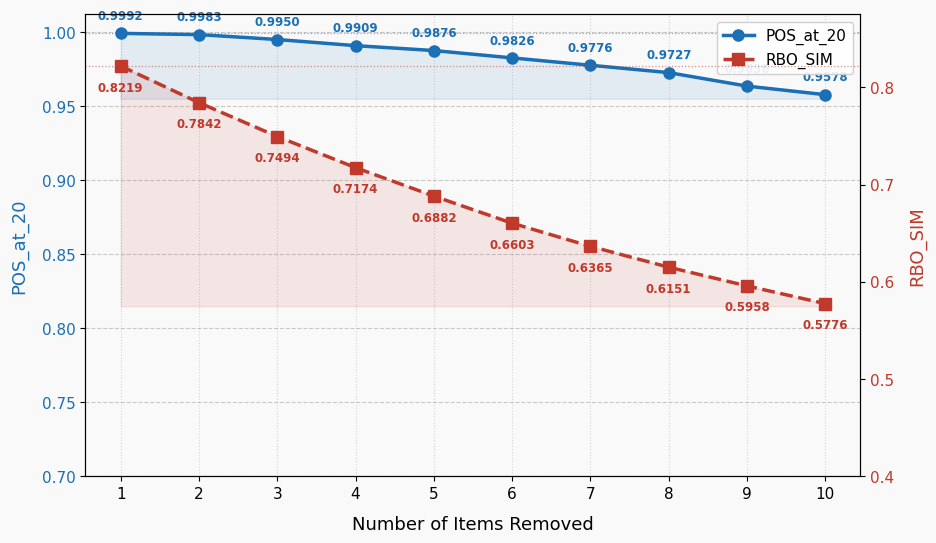

In [70]:
import numpy as np
import matplotlib.pyplot as plt


x = np.arange(1, 11)

# ── Figure setup ────────────────────────────────────────
fig, ax1 = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor('#F9F9F9')
ax1.set_facecolor('#F9F9F9')

c1, c2 = '#1A6FB5', '#C0392B'

# ── Left Y-axis: POS_at_20 ──────────────────────────────
ax1.set_xlabel('Number of Items Removed', fontsize=13, labelpad=10)
ax1.set_ylabel('POS_at_20', color=c1, fontsize=13, labelpad=10)
ax1.set_xticks(x)
ax1.set_ylim(0.7, 1.012)
ax1.tick_params(axis='y', labelcolor=c1, labelsize=11)
ax1.tick_params(axis='x', labelsize=11)

line1, = ax1.plot(x, metrics['POS_at_20'], color=c1, marker='o',
                  linewidth=2.5, markersize=8, label='POS_at_20', zorder=3)

# Shaded area under POS_at_20
ax1.fill_between(x, metrics['POS_at_20'], 0.955, alpha=0.10, color=c1)

# Baseline dotted reference line
ax1.axhline(metrics['POS_at_20'][0], color=c1, linewidth=0.9,
            linestyle=':', alpha=0.55, zorder=1)

# Annotate each data point (above the marker)
for xi, yi in zip(x, metrics['POS_at_20']):
    ax1.annotate(f'{yi:.4f}', xy=(xi, yi),
                 xytext=(0, 10), textcoords='offset points',
                 ha='center', fontsize=8.5, color=c1, fontweight='bold')

# ── Right Y-axis: RBO_SIM ───────────────────────────────
ax2 = ax1.twinx()
ax2.set_ylabel('RBO_SIM', color=c2, fontsize=13, labelpad=10)
ax2.set_ylim(0.4, 0.875)
ax2.tick_params(axis='y', labelcolor=c2, labelsize=11)

line2, = ax2.plot(x, metrics['RBO_SIM'], color=c2, marker='s',
                  linewidth=2.5, markersize=8, linestyle='--',
                  label='RBO_SIM', zorder=3)

# Shaded area under RBO_SIM
ax2.fill_between(x, metrics['RBO_SIM'], 0.575, alpha=0.10, color=c2)

# Baseline dotted reference line
ax2.axhline(metrics['RBO_SIM'][0], color=c2, linewidth=0.9,
            linestyle=':', alpha=0.55, zorder=1)

# Annotate each data point (below the marker)
for xi, yi in zip(x, metrics['RBO_SIM']):
    ax2.annotate(f'{yi:.4f}', xy=(xi, yi),
                 xytext=(0, -18), textcoords='offset points',
                 ha='center', fontsize=8.5, color=c2, fontweight='bold')

# ── % total drop callout on the last point ──────────────
drop1 = (metrics['POS_at_20'][-1] - metrics['POS_at_20'][0]) / metrics['POS_at_20'][0] * 100
drop2 = (metrics['RBO_SIM'][-1]   - metrics['RBO_SIM'][0])   / metrics['RBO_SIM'][0]   * 100

#ax1.annotate(f'Total drop: {drop1:.2f}%',
             #xy=(5, metrics['POS_at_20'][-1]),
             #xytext=(-70, -30), textcoords='offset points',
             #fontsize=9, color=c1, fontstyle='italic',
             #arrowprops=dict(arrowstyle='->', color=c1, lw=1.2))

#ax2.annotate(f'Total drop: {drop2:.2f}%',
            # xy=(5, metrics['RBO_SIM'][-1]),
             #xytext=(-70, 30), textcoords='offset points',
            # fontsize=9, color=c2, fontstyle='italic',
             #arrowprops=dict(arrowstyle='->', color=c2, lw=1.2))

# ── Grid ─────────────────────────────────────────────────
ax1.grid(axis='y', linestyle='--', alpha=0.4, color='gray')
ax1.grid(axis='x', linestyle=':',  alpha=0.3, color='gray')

# ── Legend ───────────────────────────────────────────────
lines  = [line1, line2]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right', fontsize=11,
           framealpha=0.9, edgecolor='#CCCCCC')

# ── Title ────────────────────────────────────────────────
plt.title(f'{data_name} - {recommender_name} explained by {exp_model_name}',
          fontsize=14, fontweight='bold', pad=15)

fig.tight_layout()
plt.savefig('dual_axis_improved.png', dpi=150, bbox_inches='tight')
plt.show()

In [26]:
def run_all_baselines(data_name, recommender_name):
    global num_users, num_items, device, kw_dict, recommender, test_array, test_data, items_array, jaccard_dict, cosine_dict, pop_dict, item_to_cluster, shap_values

    # Update global variables for the current dataset and recommender
    num_users = num_users_dict[data_name]
    num_items = num_items_dict[data_name]
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Load dataset-specific files
    DP_DIR = Path("processed_data", data_name)
    files_path = Path(export_dir.parent, DP_DIR)
    test_data = pd.read_csv(Path(files_path, f'test_data_{data_name}.csv'), index_col=0)
    test_array = test_data.to_numpy()
    items_array = np.eye(num_items)

    with open(Path(files_path, f'jaccard_based_sim_{data_name}.pkl'), 'rb') as f:
        jaccard_dict = pickle.load(f)
    with open(Path(files_path, f'cosine_based_sim_{data_name}.pkl'), 'rb') as f:
        cosine_dict = pickle.load(f)
    with open(Path(files_path, f'pop_dict_{data_name}.pkl'), 'rb') as f:
        pop_dict = pickle.load(f)
    with open(Path(files_path, f'item_to_cluster_{recommender_name}_{data_name}.pkl'), 'rb') as f:
        item_to_cluster = pickle.load(f)
    with open(Path(files_path, f'shap_values_{recommender_name}_{data_name}.pkl'), 'rb') as f:
        shap_values = pickle.load(f)

    # Update kw_dict
    kw_dict = {
        'device': device,
        'num_items': num_items,
        'num_features': num_items,
        'demographic': False,
        'pop_array': np.array([pop_dict.get(i, 0) for i in range(num_items)]),
        'all_items_tensor': torch.eye(num_items).to(device),
        'static_test_data': test_data,
        'items_array': items_array,
        'output_type': output_type_dict[recommender_name],
        'recommender_name': recommender_name,
        'files_path': files_path
    }

    # Load recommender
    recommender = load_recommender()

    # Run all baselines
    baselines = [ 'jaccard', 'cosine', 'lime', 'lxr', 'accent', 'shap']
    results = {}

    for baseline in baselines:
        print(f"Running {baseline} baseline for {data_name} {recommender_name}")
        results[baseline] = eval_one_expl_type(baseline)

    return results

In [27]:
def plot_all_metrics(results, data_name, recommender_name):
    # Mapping between metric keys and their display names (title, y-label, indicator)
    metrics_mapping = {
        'DEL':      ('AUC DEL-P@K', 'DEL@Kₑ', 'Lower is better'),
        'INS':      ('AUC INS-P@K', 'INS@Kₑ', 'Higher is better'),
        'NDCG':     ('AUC NDCG-P',  'CNDCG@Kₑ', 'Lower is better'),
        'POS_at_5': ('AUC POS-P@5', 'POS@20Kₑ', 'Lower is better'),
        'POS_at_10':('AUC POS-P@10','POS@20Kₑ', 'Lower is better'),
        'POS_at_20':('AUC POS-P@20','POS@20Kₑ', 'Lower is better'),
        'NEG_at_5': ('AUC NEG-P@5', 'NEG@20Kₑ', 'Higher is better'),
        'NEG_at_10':('AUC NEG-P@10','NEG@20Kₑ', 'Higher is better'),
        'NEG_at_20':('AUC NEG-P@20','NEG@20Kₑ', 'Higher is better')
    }
    
    # Style lists
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
    markers = ['o', 's', '^', 'D', 'v', 'x']
    linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1)), (0, (5, 2))]
    
    # Create plots directory
    os.makedirs('plots_discrete', exist_ok=True)
    
    # Plot each metric
    for metric, (title_name, y_label, indicator) in metrics_mapping.items():
        plt.figure(figsize=(12, 8))
        
        for i, (baseline, baseline_metrics) in enumerate(results.items()):
            if metric not in baseline_metrics:
                print(f"Warning: {metric} not found in {baseline} metrics")
                continue
            
            values = baseline_metrics[metric][:5]  # Take only first 5 values
            x = range(1, len(values) + 1)  # Numbers of masked items (1, 2, 3, 4, 5)
            
            plt.plot(
                x, values,
                label=baseline.upper(),
                color=colors[i % len(colors)],
                linestyle=linestyles[i % len(linestyles)],
                marker=markers[i % len(markers)],
                markersize=8,
                linewidth=2,
                markevery=1  # Markers on each value
            )
        
        plt.xlabel("Number of Masked Items", fontsize=30)
        plt.ylabel(y_label, fontsize=30)
        plt.grid(True, linestyle='--', alpha=0.7, linewidth=0.5)
        plt.xticks(range(1, 6), fontsize=18)
        plt.yticks(fontsize=18)
        plt.legend(
            loc='best', 
            fontsize=20,
            frameon=True,
            edgecolor='black'
        )

        plt.tight_layout()
        
        # Save the plot
        safe_display_name = title_name.replace(" ", "_").replace("@", "at")
        plt.savefig(f'plots_discrete/{safe_display_name}_{data_name}_{recommender_name}d.pdf',
                    format='pdf', bbox_inches='tight')
        print(f"Saved plot: {safe_display_name}_{data_name}_{recommender_name}d.pdf")
        plt.close()

In [ ]:
def process_recommender(data_name, recommender_name):
    DP_DIR = Path("processed_data", data_name)
    #files_path = Path("/storage/mikhail/PI4Rec", DP_DIR)
    
    num_users = num_users_dict[data_name]
    num_items = num_items_dict[data_name]
    num_features = num_items_dict[data_name]
    
    with open(Path(files_path, f'pop_dict_{data_name}.pkl'), 'rb') as f:
        pop_dict = pickle.load(f)
    pop_array = np.zeros(len(pop_dict))
    for key, value in pop_dict.items():
        pop_array[key] = value

    test_data = pd.read_csv(Path(files_path,f'test_data_{data_name}.csv'), index_col=0)
    static_test_data = pd.read_csv(Path(files_path,f'static_test_data_{data_name}.csv'), index_col=0)
    
    test_array = static_test_data.iloc[:,:-2].to_numpy()
    items_array = np.eye(num_items)
    
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    all_items_tensor = torch.Tensor(items_array).to(device)

    output_type = output_type_dict[recommender_name]
    hidden_dim = hidden_dim_dict[(data_name,recommender_name)]
    recommender_path = recommender_path_dict[(data_name,recommender_name)]

    kw_dict = {
        'device': device,
        'num_items': num_items,
        'demographic': False,
        'num_features': num_features,
        'pop_array': pop_array,
        'all_items_tensor': all_items_tensor,
        'static_test_data': static_test_data,
        'items_array': items_array,
        'output_type': output_type,
        'recommender_name': recommender_name,
        'files_path': files_path
    }

    recommender = load_recommender()

    print(f"Processing {data_name} dataset with {recommender_name} recommender")
    
    results = {}
    for expl_name in [ 'jaccard', 'cosine', 'lime', 'lxr', 'accent', 'shap']:
        results[expl_name] = eval_one_expl_type(expl_name, data_name, recommender_name, test_array, test_data, items_array, recommender, kw_dict)
    
   # plot_all_metrics(results, data_name, recommender_name)

In [29]:
from openpyxl import Workbook
from openpyxl.styles import Font, Alignment, Border, Side

def save_results_to_excel(results, filename):
    wb = Workbook()
    
    # Create MF recommender sheet
    ws_mf = wb.active
    ws_mf.title = "MF Recommender"
    
    # Create VAE recommender sheet
    ws_vae = wb.create_sheet(title="VAE Recommender")
    
    for ws, title in [(ws_mf, "AUC values for explaining an MF recommender."), 
                      (ws_vae, "AUC values for explaining a VAE recommender.")]:
        
        # Add title
        ws['A1'] = f"Table: {title}"
        ws['A1'].font = Font(bold=True)
        ws.merge_cells('A1:G1')
        
        # Add headers
        headers = ['Method', 'k=5', 'k=10', 'k=20', 'DEL', 'INS', 'NDCG']
        for col, header in enumerate(headers, start=1):
            ws.cell(row=3, column=col, value=header).font = Font(bold=True)
        
        # Add data
        for row, (method, values) in enumerate(results.items(), start=4):
            ws.cell(row=row, column=1, value=method)
            for col, value in enumerate(values, start=2):
                ws.cell(row=row, column=col, value=value)
    
    # Apply some styling
    for ws in [ws_mf, ws_vae]:
        for row in ws[f'A3:G{ws.max_row}']:
            for cell in row:
                cell.border = Border(left=Side(style='thin'), 
                                     right=Side(style='thin'), 
                                     top=Side(style='thin'), 
                                     bottom=Side(style='thin'))
    
    wb.save(filename)

def run_and_format_results(data_name, recommender_name):
    results = {}
    for expl_name in ['jaccard', 'cosine', 'lime', 'shap', 'accent', 'lxr']:
        raw_results = eval_one_expl_type(expl_name)
        
        # Extract POS values
        pos_at_5 = raw_results['POS_at_5'][-1]  # Last value represents 100% of items
        pos_at_10 = raw_results['POS_at_10'][-1]
        pos_at_20 = raw_results['POS_at_20'][-1]
        
        # Format results as per the desired output
        results[expl_name.upper()] = [
            pos_at_5,
            pos_at_10,
            pos_at_20,
            raw_results['DEL'][-1],
            raw_results['INS'][-1],
            raw_results['NDCG'][-1]
        ]
    
    return results

In [32]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

def create_comparison_visualizations(all_results, save_dir='./'): 
    """
    Creates comprehensive visualizations comparing methods across datasets and recommenders
    
    Parameters:
    all_results: dict
        Format: {(dataset_name, recommender_name): results_dict}
        where results_dict contains metrics for each explanation method
    save_dir: str
        Directory to save the visualization files
    """
    # Prepare data for plotting
    plot_data = []
    for (dataset, recommender), results in all_results.items():
        for method, metrics in results.items():
            for metric_name, values in metrics.items():
                if isinstance(values, np.ndarray):
                    for step, value in enumerate(values, 1):
                        plot_data.append({
                            'Dataset': dataset,
                            'Recommender': recommender,
                            'Method': method.upper(),
                            'Metric': metric_name,
                            'Step': step,
                            'Value': value
                        })
    
    df = pd.DataFrame(plot_data)

    # 1. Heatmap of method performance across datasets and recommenders
    plt.figure(figsize=(15, 10))
    metrics_to_plot = ['DEL', 'INS', 'NDCG']
    
    for idx, metric in enumerate(metrics_to_plot):
        plt.subplot(1, 3, idx+1)
        pivot_data = df[df['Metric'] == metric].groupby(
            ['Dataset', 'Recommender', 'Method'])['Value'].mean().unstack()
        sns.heatmap(pivot_data, annot=True, fmt='.3f', cmap='YlOrRd')
        plt.title(f'{metric} Performance Comparison')
    
    plt.tight_layout()
    plt.savefig(f'{save_dir}/performance_heatmap.png')
    plt.close()

    # 2. Method stability analysis (standard deviation across steps)
    plt.figure(figsize=(12, 6))
    stability_data = df.groupby(['Method', 'Metric'])['Value'].std().unstack()
    stability_data.plot(kind='bar', width=0.8)
    plt.title('Method Stability Analysis (Standard Deviation Across Steps)')
    plt.xlabel('Explanation Method')
    plt.ylabel('Standard Deviation')
    plt.xticks(rotation=45)
    plt.legend(title='Metrics', bbox_to_anchor=(1.05, 1))
    plt.tight_layout()
    plt.savefig(f'{save_dir}/method_stability.png')
    plt.close()

    # 3. Radar chart for method comparison
    def create_radar_chart(data, methods, metrics):
        angles = np.linspace(0, 2*np.pi, len(metrics), endpoint=False)
        fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(projection='polar'))
        
        for method in methods:
            values = [data[(data['Method'] == method) & 
                          (data['Metric'] == metric)]['Value'].mean() 
                     for metric in metrics]
            values += values[:1]
            angles_plot = np.concatenate([angles, [angles[0]]])
            ax.plot(angles_plot, values, 'o-', label=method)
            ax.fill(angles_plot, values, alpha=0.25)
        
        ax.set_xticks(angles)
        ax.set_xticklabels(metrics)
        ax.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
        
        return fig

    metrics_for_radar = ['DEL', 'INS', 'NDCG', 'POS_at_5', 'POS_at_10']
    for dataset in df['Dataset'].unique():
        for recommender in df['Recommender'].unique():
            data_subset = df[(df['Dataset'] == dataset) & 
                           (df['Recommender'] == recommender)]
            fig = create_radar_chart(data_subset, 
                                   df['Method'].unique(), 
                                   metrics_for_radar)
            plt.title(f'{dataset} - {recommender}\nMethod Comparison')
            plt.savefig(f'{save_dir}/radar_{dataset}_{recommender}.png')
            plt.close()

    # 4. Box plots showing distribution of metrics across steps
    plt.figure(figsize=(15, 10))
    for idx, metric in enumerate(['DEL', 'INS', 'NDCG'], 1):
        plt.subplot(1, 3, idx)
        sns.boxplot(data=df[df['Metric'] == metric], 
                   x='Method', y='Value', 
                   hue='Dataset')
        plt.title(f'{metric} Distribution')
        plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(f'{save_dir}/metric_distributions.png')
    plt.close()

    # 5. Performance improvement over steps
    plt.figure(figsize=(15, 8))
    for metric in ['DEL', 'INS', 'NDCG']:
        plt.subplot(1, 3, metrics_to_plot.index(metric) + 1)
        for method in df['Method'].unique():
            data = df[(df['Metric'] == metric) & (df['Method'] == method)]
            plt.plot(data.groupby('Step')['Value'].mean(), 
                    marker='o', 
                    label=method)
        plt.title(f'{metric} Progress Over Steps')
        plt.xlabel('Step')
        plt.ylabel('Value')
        if metric == 'NDCG':
            plt.legend(bbox_to_anchor=(1.05, 1))
    plt.tight_layout()
    plt.savefig(f'{save_dir}/progress_over_steps.png')
    plt.close()

    return df

def generate_summary_report(df, save_dir='./'):
    """
    Generates a statistical summary report of the results
    """
    # Calculate aggregate statistics
    summary = df.groupby(['Dataset', 'Recommender', 'Method', 'Metric'])['Value'].agg([
        'mean', 'std', 'min', 'max'
    ]).round(3)
    
    # Save summary to CSV
    summary.to_csv(f'{save_dir}/summary_statistics.csv')
    
    # Calculate method rankings
    rankings = df.groupby(['Dataset', 'Recommender', 'Method', 'Metric'])['Value'].mean().unstack()
    method_ranks = rankings.rank(ascending=False, method='min')
    method_ranks.to_csv(f'{save_dir}/method_rankings.csv')
    
    return summary, method_ranks

In [33]:
def create_results_table(results, data_name, recommender_name):
    """
    Create a comprehensive table of all metrics for each method and masking step
    """
    # Initialize the table structure
    table_data = []
    metrics = ['DEL', 'INS', 'NDCG', 'POS_at_5', 'POS_at_10', 'POS_at_20']
    
    for method in results.keys():
        for step in range(5):  # 5 steps
            row = {
                'Method': method.upper(),
                'Step': step + 1,  # 1-based indexing
                'Dataset': data_name,
                'Recommender': recommender_name
            }
            
            # Add all metrics for this method and step
            for metric in metrics:
                row[metric] = results[method][metric][step]
            
            table_data.append(row)
    
    # Create DataFrame
    df = pd.DataFrame(table_data)
    
    # Save to CSV
    csv_filename = f'results_{data_name}_{recommender_name}.csv'
    df.to_csv(csv_filename, index=False)
    
    # Create and save a formatted Excel file
    wb = Workbook()
    ws = wb.active
    ws.title = f"{data_name}_{recommender_name}_Results"
    
    # Add title (in row 1)
    ws['A1'] = f"Results for {data_name} dataset with {recommender_name} recommender"
    ws.merge_cells('A1:H1')
    ws['A1'].font = Font(bold=True)
    
    # Add headers (in row 3)
    headers = ['Method', 'Step', 'DEL', 'INS', 'NDCG', 'POS@5', 'POS@10', 'POS@20']
    for col, header in enumerate(headers, 1):
        cell = ws.cell(row=3, column=col, value=header)
        cell.font = Font(bold=True)
    
    # Add data with formatting
    current_method = None
    row_num = 4
    for _, row in df.iterrows():
        if current_method != row['Method']:
            current_method = row['Method']
            row_num += 1  # Add space between methods
        
        ws.cell(row=row_num, column=1, value=row['Method'])
        ws.cell(row=row_num, column=2, value=row['Step'])
        ws.cell(row=row_num, column=3, value=float(row['DEL']))
        ws.cell(row=row_num, column=4, value=float(row['INS']))
        ws.cell(row=row_num, column=5, value=float(row['NDCG']))
        ws.cell(row=row_num, column=6, value=float(row['POS_at_5']))
        ws.cell(row=row_num, column=7, value=float(row['POS_at_10']))
        ws.cell(row=row_num, column=8, value=float(row['POS_at_20']))
        
        row_num += 1
    
    # Apply formatting to all cells
    for row in ws.iter_rows(min_row=3, max_row=row_num-1):
        for cell in row:
            cell.border = Border(
                left=Side(style='thin'),
                right=Side(style='thin'),
                top=Side(style='thin'),
                bottom=Side(style='thin')
            )
            if isinstance(cell.value, float):
                cell.number_format = '0.000'
    
    # Adjust column widths (skip merged cells)
    column_widths = {}
    for row in ws.iter_rows(min_row=3):  # Start from row 3 to skip merged cells
        for cell in row:
            if isinstance(cell, MergedCell):
                continue
            col = cell.column_letter
            width = len(str(cell.value)) + 2
            current_width = column_widths.get(col, 0)
            column_widths[col] = max(current_width, width)
    
    # Apply the calculated widths
    for col, width in column_widths.items():
        ws.column_dimensions[col].width = width
    
    # Save Excel file
    excel_filename = f'results_{data_name}_{recommender_name}.xlsx'
    wb.save(excel_filename)
    
    # Return DataFrame for further analysis if needed
    return df

def print_summary_statistics(df):
    """
    Print summary statistics for each method
    """
    print("\nSummary Statistics:")
    print("=" * 80)
    
    methods = df['Method'].unique()
    metrics = ['DEL', 'INS', 'NDCG', 'POS_at_5', 'POS_at_10', 'POS_at_20']
    
    summary_rows = []
    for method in methods:
        method_data = df[df['Method'] == method]
        row = {'Method': method}
        
        for metric in metrics:
            row[f'{metric}_Mean'] = method_data[metric].mean()
            row[f'{metric}_Std'] = method_data[metric].std()
        
        summary_rows.append(row)
    
    summary_df = pd.DataFrame(summary_rows)
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', None)
    print(summary_df.round(3))
    return summary_df



# Use the functions
def generate_tables(results, data_name, recommender_name):
    df = create_results_table(results, data_name, recommender_name)
    summary_df = print_summary_statistics(df)
    return df, summary_df

In [ ]:
data_names = ["ML1M"]#, ,"Yahoo","Pinterest"
recommender_names = [ "MLP"]#"MLP""VAE", "NCF"

# Create a mapping between explainer names and actual explainer functions
explainer_mapping = {
   # 'pop': find_pop_mask,
   # 'jaccard': find_jaccard_mask,
    #'cosine': find_cosine_mask,
    #'lime': find_lime_mask,
    #'lire': find_lire_mask,
    'lxr': find_lxr_mask,
    #'accent': find_accent_mask,
    #'shap': find_shapley_mask
}

# Initialize storage for all results
# Initialize storage for all results
all_results = {}

# Create plots directory
plots_dir = Path('plots_discrete')
plots_dir.mkdir(exist_ok=True)

for data_name in data_names:
    DP_DIR = Path("processed_data", data_name)
    #files_path = Path("/storage/mikhail/PI4Rec", DP_DIR)

    # Load dataset-specific parameters and data
    num_users = num_users_dict[data_name] 
    num_items = num_items_dict[data_name] 
    num_features = num_items_dict[data_name]
        
    with open(Path(files_path, f'pop_dict_{data_name}.pkl'), 'rb') as f:
        pop_dict = pickle.load(f)
    pop_array = np.zeros(len(pop_dict))
    for key, value in pop_dict.items():
        pop_array[key] = value

    # Load data files
    train_data = pd.read_csv(Path(files_path,f'train_data_{data_name}.csv'), index_col=0)
    test_data = pd.read_csv(Path(files_path,f'test_data_{data_name}.csv'), index_col=0)
    static_test_data = pd.read_csv(Path(files_path,f'static_test_data_{data_name}.csv'), index_col=0)
    
    train_array = train_data.to_numpy()
    test_array = test_data.to_numpy()
    items_array = np.eye(num_items)
    all_items_tensor = torch.Tensor(items_array).to(device)
    test_array = static_test_data.iloc[:,:-2].to_numpy()

    for recommender_name in recommender_names:
        print(f"\nProcessing {data_name} dataset with {recommender_name} recommender")
        
        # Set up recommender-specific parameters
        output_type = output_type_dict[recommender_name]
        hidden_dim = hidden_dim_dict[(data_name,recommender_name)]
        recommender_path = recommender_path_dict[(data_name,recommender_name)]

        kw_dict = {
            'device': device,
            'num_items': num_items,
            'demographic': False,
            'num_features': num_features,
            'pop_array': pop_array,
            'all_items_tensor': all_items_tensor,
            'static_test_data': static_test_data,
            'items_array': items_array,
            'output_type': output_type,
            'recommender_name': recommender_name
        }

        recommender = load_recommender()

        # Process each explanation method
        results = {}
        for expl_name in ['jaccard', 'cosine', 'lime', 'lxr', 'accent', 'shap']:
            try:
                results[expl_name] = eval_one_expl_type(expl_name)
                # Take only first 5 values from each metric array
                results[expl_name] = {
                    metric: values[:5] if len(values) >= 5 else values 
                    for metric, values in results[expl_name].items()
                }
            except Exception as e:
                print(f"Error processing {expl_name} for {data_name} {recommender_name}: {str(e)}")
                continue

        # Store results in the overall dictionary
        all_results[(data_name, recommender_name)] = results
        
        # Generate and save plots
        plot_all_metrics(results, data_name, recommender_name)

print("\nProcessing complete. Results and visualizations have been saved to plots_discrete directory.")

FileNotFoundError: [Errno 2] No such file or directory: '/storage/mikhail/PI4Rec/processed_data/ML1M/pop_dict_ML1M.pkl'

In [33]:
plot_all_metrics(results, data_name, recommender_name)

Saved plot: AUC_DEL-PatK_ML1M_MLPd.pdf
Saved plot: AUC_INS-PatK_ML1M_MLPd.pdf
Saved plot: AUC_NDCG-P_ML1M_MLPd.pdf
Saved plot: AUC_POS-Pat5_ML1M_MLPd.pdf
Saved plot: AUC_POS-Pat10_ML1M_MLPd.pdf
Saved plot: AUC_POS-Pat20_ML1M_MLPd.pdf
Saved plot: AUC_NEG-Pat5_ML1M_MLPd.pdf
Saved plot: AUC_NEG-Pat10_ML1M_MLPd.pdf
Saved plot: AUC_NEG-Pat20_ML1M_MLPd.pdf


In [34]:
create_results_table(results, data_name, recommender_name)

,Method,Step,Dataset,Recommender,DEL,INS,NDCG,POS_at_5,POS_at_10,POS_at_20
0,JACCARD,1,ML1M,MLP,0.970001,0.666879,0.973947,0.998344,0.999172,0.999172
1,JACCARD,2,ML1M,MLP,0.963509,0.703173,0.954638,0.995033,0.997517,0.998344
2,JACCARD,3,ML1M,MLP,0.956697,0.733510,0.937319,0.989238,0.995033,0.997517
3,JACCARD,4,ML1M,MLP,0.949667,0.758765,0.916401,0.973510,0.992550,0.995861
4,JACCARD,5,ML1M,MLP,0.942137,0.780008,0.900209,0.963576,0.987583,0.995861
5,COSINE,1,ML1M,MLP,0.968171,0.685167,0.948745,0.997517,1.000000,1.000000
6,COSINE,2,ML1M,MLP,0.960639,0.730850,0.914627,0.986755,0.995861,0.998344
7,COSINE,3,ML1M,MLP,0.952149,0.765268,0.882621,0.964404,0.987583,0.993377
8,COSINE,4,ML1M,MLP,0.943702,0.791354,0.860932,0.944536,0.973510,0.987583
9,COSINE,5,ML1M,MLP,0.934919,0.811589,0.840398,0.934603,0.957781,0.978477
